# 03 - Second-Purchase (Churn) Model

**Business question:** *Will a new customer come back for a second purchase within N days of the first one?*

Why not "classic" churn? 97.8% of customers bought on a single day, so almost everyone looks "churned" after the first order. The useful question for the business is the **second purchase**: if we can rank new customers by their chance of coming back, marketing can focus the second-purchase offer on the right people (see the *New high-value* segment in `02_rfm_segmentation.ipynb`).

- **Target = 1** if the customer bought again on a **different day** within the window (same-day orders are split baskets, not returns).
- **Churn probability** = 1 - probability of returning.
- Data: `rpt.vw_CustomerOrders` (delivered orders only).


## 1. Load data and build each customer's purchase days


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path
from db_utils import read_view

sns.set_theme(style="whitegrid")
plt.rcParams["axes.titleweight"] = "bold"
BLUE = "#2a78d6"
IMG_DIR = Path("../images")

orders = read_view("vw_CustomerOrders")
orders["purchase_date"] = pd.to_datetime(orders["purchase_date"])
DATA_END = orders["purchase_date"].max()

# One row per customer per purchase DAY (same-day orders collapse into one)
days = (orders[["customer_key", "purchase_date"]].drop_duplicates()
        .sort_values(["customer_key", "purchase_date"]))
days["day_seq"] = days.groupby("customer_key").cumcount() + 1

cust = (days[days["day_seq"] == 1].set_index("customer_key")[["purchase_date"]]
        .rename(columns={"purchase_date": "first_date"})
        .join(days[days["day_seq"] == 2].set_index("customer_key")["purchase_date"].rename("second_date")))
cust["gap_days"] = (cust["second_date"] - cust["first_date"]).dt.days

print(f"Data ends: {DATA_END.date()}")
print(f"Customers: {len(cust):,} | with a 2nd purchase day: {cust['second_date'].notna().sum():,}")

Data ends: 2018-08-29
Customers: 93,350 | with a 2nd purchase day: 2,015


## 2. How long should the window be?

If the window is too short we miss many real returns; if it is too long, too few customers have enough history to be labelled.
To measure this fairly we only use customers whose first purchase was **at least 365 days before the data ends**, so everyone had a full year to come back.


Customers with 365+ days of history: 21,360 | of them returned (any time): 795

             returned_within_%  share_of_all_returns_%
window_days                                           
30                        0.68                   18.24
60                        1.06                   28.43
90                        1.35                   36.23
120                       1.62                   43.52
180                       2.13                   57.36
270                       2.75                   73.84
365                       3.33                   89.43


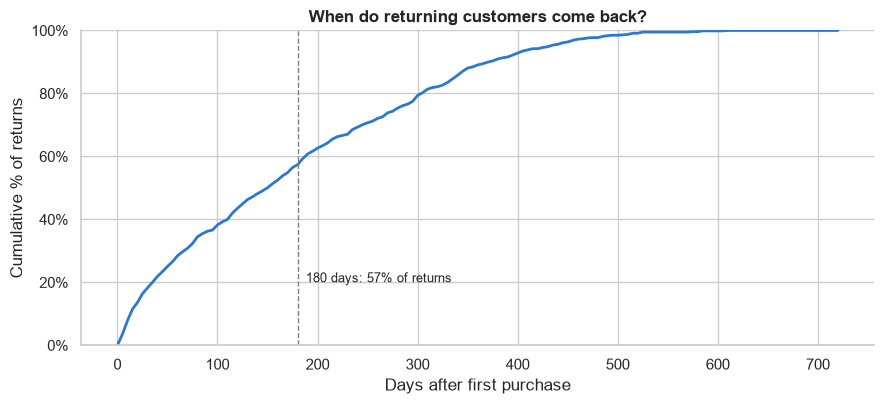

In [2]:
old = cust[cust["first_date"] <= DATA_END - pd.Timedelta(days=365)]
returners = old["gap_days"].dropna()
print(f"Customers with 365+ days of history: {len(old):,} | of them returned (any time): {len(returners):,}\n")

windows = [30, 60, 90, 120, 180, 270, 365]
coverage = pd.DataFrame({
    "window_days": windows,
    "returned_within_%": [(old["gap_days"] <= w).mean() * 100 for w in windows],
    "share_of_all_returns_%": [(returners <= w).mean() * 100 for w in windows],
}).set_index("window_days")
print(coverage.round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 4.2))
steps = np.arange(0, 721, 5)
ax.plot(steps, [(returners <= d).mean() * 100 for d in steps], color=BLUE, lw=2)
ax.axvline(180, color="gray", ls="--", lw=1)
ax.annotate(f"180 days: {(returners <= 180).mean():.0%} of returns", (180, 20), xytext=(6, 0),
            textcoords="offset points", fontsize=9)
ax.set_title("When do returning customers come back?")
ax.set_xlabel("Days after first purchase")
ax.set_ylabel("Cumulative % of returns")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, 100)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(IMG_DIR / "10_return_window.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Final target definition

- **Window = 180 days** after the first purchase.
- **Eligible customers**: first purchase between **2017-01-01** and **DATA_END - 180 days**, so every customer has the full 180 days observed (no customer is labelled "did not return" just because the data ended). 2016 is excluded because it has almost no orders.
- `returned_180 = 1` if the 2nd purchase day is within 180 days, else 0.


In [3]:
WINDOW = 180
LAST_FIRST_DATE = DATA_END - pd.Timedelta(days=WINDOW)

model_base = cust[(cust["first_date"] >= "2017-01-01") & (cust["first_date"] <= LAST_FIRST_DATE)].copy()
model_base["returned_180"] = (model_base["gap_days"] <= WINDOW).astype(int)   # NaN gap -> 0

n, pos = len(model_base), model_base["returned_180"].sum()
print(f"Eligible first purchases: {model_base['first_date'].min().date()} -> {model_base['first_date'].max().date()}")
print(f"Customers: {n:,} | returned within {WINDOW} days: {pos:,} ({pos / n:.2%}) | did not: {n - pos:,}")
print(f"Class ratio: about 1 returner for every {round((n - pos) / pos)} non-returners")

# Is the return rate stable over time? (a model trained on one period must work on another)
by_q = (model_base.groupby(model_base["first_date"].dt.to_period("Q"))["returned_180"]
        .agg(customers="size", return_rate_pct=lambda s: s.mean() * 100))
print()
print(by_q.round(2).to_string())

Eligible first purchases: 2017-01-05 -> 2018-03-02
Customers: 55,770 | returned within 180 days: 1,107 (1.98%) | did not: 54,663
Class ratio: about 1 returner for every 49 non-returners

            customers  return_rate_pct
first_date                            
2017Q1           4848             1.73
2017Q2           8743             2.24
2017Q3          11813             2.36
2017Q4          16725             1.76
2018Q1          13641             1.85


**Insight - the target is rare, stable over time, and the 180-day window is a deliberate trade-off**

- Among customers with a full year of history, only **3.3%** came back within 365 days. Returns are spread out: **30 days** catch 18% of them, **90 days** 36%, **180 days 57%**, 270 days 74%, 365 days 89%.
- **Why 180 days anyway?**
  - A longer window leaves fewer customers with enough history: 365 days would keep only first purchases up to Aug 2017 (~21k customers, ~700 returners) and no 2018 data at all.
  - 180 days keeps **55,770 customers** and **1,107 returners**, and includes **2018 Q1**, which we need to test the model on a later period than it was trained on.
  - Six months is a practical horizon for a marketing campaign.
  - So the model answers exactly: *"Will this customer return within 6 months?"*, not *"Will they ever return?"*. Some customers labelled 0 will come back later; that is a known limitation, stated clearly.
- **Base rate: 1.98%** (about 1 returner for every 49 non-returners). A model that always says "will not return" would be **98% accurate and useless**, so in 2.7-2.8 we will use **class weights** and judge the model with **Precision, Recall, ROC-AUC and PR-AUC**, never accuracy.
- The return rate is **stable across quarters (1.7%-2.4%)**, so training on 2017 and testing on 2018 Q1 is a fair check.
